# Aufgabe 2 · Objekterkennung auf KITTI

YOLOv8n startet mit zufälligen Gewichten und sieht pro Epoche 40 KITTI-Bilder. Die zehn zurückgehaltenen Bilder dienen zur Validierung und zum CPU-Benchmark. Drei Epochen reichen für einen Funktionstest.

In [1]:
from collections import Counter
from time import perf_counter

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Patch, Rectangle
from matplotlib_inline.backend_inline import set_matplotlib_formats
from PIL import Image
from ultralytics import YOLO

from src.kitti import CLASSES, SPLIT, annotations, image_path
from src.train_kitti_yolo import train

set_matplotlib_formats("jpeg")
weights = train()
model = YOLO(weights)
settings = dict(device="cpu", imgsz=320, verbose=False, save=False)
example_id = SPLIT["val"][0]
example = image_path(example_id)
with Image.open(example) as photo:
    pixels = photo.convert("RGB")
width, height = pixels.size
display(pixels)

## Eine Erkennung lesen

Für das erste Validierungsbild zeigen wir Klasse, Konfidenz und Box der sichersten Erkennung über der Schwelle von 0,25.

In [2]:
result = model.predict(example, conf=0.25, **settings)[0]
predictions = result.summary()
if predictions:
    first = max(predictions, key=lambda obj: obj["confidence"])
    display(first)
    box = first["box"]
    display(pixels.crop((box["x1"], box["y1"], box["x2"], box["y2"])))
else:
    print("Keine Vorhersage erreicht 0,25 Konfidenz.")

Keine Vorhersage erreicht 0,25 Konfidenz.


## Vorhersagen mit KITTI vergleichen

Links stehen die Vorhersagen, rechts die annotierten Boxen der vier Versuchsklassen. Mit `min_confidence` lässt sich die Anzeigeschwelle erhöhen.

In [3]:
reference = [
    {"name": name, "box": dict(zip(("x1", "y1", "x2", "y2"), box))}
    for name, box in annotations(example_id, width, height)
]

In [4]:
min_confidence = 0.25
assert 0.25 <= min_confidence <= 1, "wähle einen wert zwischen 0.25 und 1."
visible = [obj for obj in predictions if obj["confidence"] >= min_confidence]
colors = {"Car": "#00dcff", "Truck": "#ffa600", "Cyclist": "#ed79ff", "Pedestrian": "#9fff61"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax, objects, title in zip(axes, [visible, reference], ["yolov8n", "KITTI"]):
    ax.imshow(pixels)
    for obj in objects:
        b = obj["box"]
        ax.add_patch(Rectangle((b["x1"], b["y1"]), b["x2"] - b["x1"], b["y2"] - b["y1"],
                               fill=False, edgecolor=colors[obj["name"]], linewidth=1.8))
    ax.set_title(f"{title} · {len(objects)} boxen")
    ax.axis("off")
fig.legend(handles=[Patch(color=colors[c], label=c) for c in CLASSES],
           loc="outside lower center", ncols=4)
plt.show()

In [5]:
counts = pd.DataFrame({
    "yolov8n": Counter(obj["name"] for obj in visible),
    "KITTI": Counter(obj["name"] for obj in reference),
}, index=list(CLASSES)).fillna(0).astype(int)
counts["differenz"] = counts["yolov8n"] - counts["KITTI"]
display(counts)

,yolov8n,KITTI,differenz
Car,0,2,-2
Truck,0,0,0
Cyclist,0,0,0
Pedestrian,0,0,0


## Batchgrößen auf der CPU testen

Wir laden die zehn Validierungsbilder einmal, wärmen jede Batchgröße auf und messen vier Durchläufe pro Größe mit 320 × 320 Pixeln. Die Reihenfolge der Batchgrößen wechselt pro Runde.

In [6]:
paths = [image_path(i) for i in SPLIT["val"]]
frames = [cv2.imread(str(path)) for path in paths]
assert all(frame is not None for frame in frames)

batch_sizes = [1, 2, 5, 10]
benchmark = dict(settings, rect=False, conf=0.25)
for size in batch_sizes:
    model.predict(frames[:size], **benchmark)

print(f"cpu · {torch.get_num_threads()} torch-threads")

cpu · 8 torch-threads


In [7]:
measurements = []
for repeat in range(len(batch_sizes)):
    order = batch_sizes[repeat:] + batch_sizes[:repeat]
    for size in order:
        for start in range(0, len(frames), size):
            batch = frames[start:start + size]
            begin = perf_counter()
            results = model.predict(batch, **benchmark)
            elapsed = perf_counter() - begin
            assert len(results) == len(batch) == size
            measurements.append({
                "batch": size, "runde": repeat + 1, "bilder": len(batch),
                "aufruf_ms": 1000 * elapsed,
                "netz_ms_pro_bild": results[0].speed["inference"],
            })

latenz misst hier die zeit vom aufruf von `predict()` bis die ergebnisse des ganzen batches vorliegen. das einlesen der bilder und das warten auf weitere kamerabilder liegen außerhalb der messung. p50 ist der median. p95 zeigt, wie lange rund 95 % der aufrufe höchstens dauern.

In [8]:
timings = pd.DataFrame(measurements)
by_size = timings.groupby("batch")
summary = by_size.agg(aufrufe=("bilder", "size"), bilder=("bilder", "sum"),
                      p50_ms=("aufruf_ms", "median"),
                      p95_ms=("aufruf_ms", lambda s: s.quantile(0.95)),
                      netz_ms_pro_bild=("netz_ms_pro_bild", "mean"))
summary["gesamt_ms_pro_bild"] = by_size["aufruf_ms"].sum() / summary["bilder"]
summary["bilder_pro_s"] = 1000 / summary["gesamt_ms_pro_bild"]
assert (summary["bilder"] == len(frames) * len(batch_sizes)).all()
display(summary.round(2))

,aufrufe,bilder,p50_ms,p95_ms,netz_ms_pro_bild,gesamt_ms_pro_bild,bilder_pro_s
batch,,,,,,,
1,40,40,11.23,11.90,10.68,11.29,88.61
2,20,40,20.78,21.43,9.98,10.41,96.06
5,8,40,37.93,42.72,7.48,7.78,128.53
10,4,40,66.78,68.53,6.47,6.72,148.92


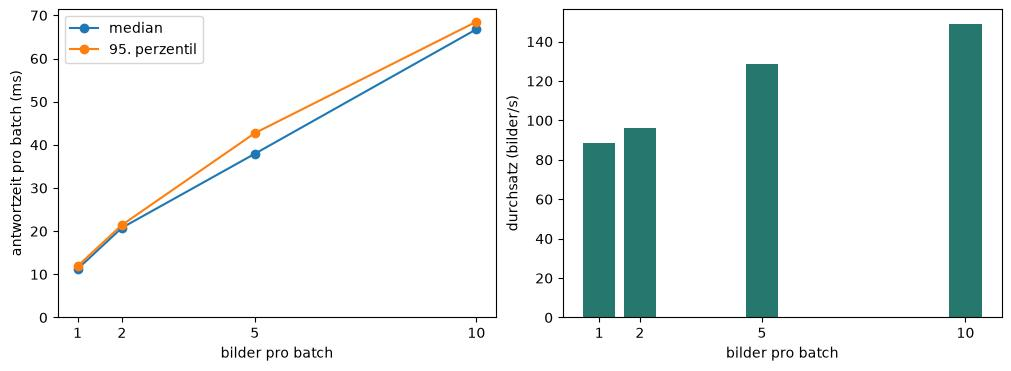

kürzeste mediane antwortzeit: batch 1 (11.2 ms).
höchster gemessener durchsatz: batch 10 (148.9 bilder/s).


In [9]:
fig, (latency, throughput) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for col, label in [("p50_ms", "median"), ("p95_ms", "95. perzentil")]:
    latency.plot(summary.index, summary[col], marker="o", label=label)
latency.set_ylabel("antwortzeit pro batch (ms)")
latency.legend()
throughput.bar(summary.index, summary["bilder_pro_s"], color="#26776e")
throughput.set_ylabel("durchsatz (bilder/s)")
for ax in (latency, throughput):
    ax.set_xlabel("bilder pro batch")
    ax.set_xticks(batch_sizes)
    ax.set_ylim(bottom=0)
plt.show()

quick = summary.p50_ms.idxmin()
fast = summary.bilder_pro_s.idxmax()
print(f"kürzeste mediane antwortzeit: batch {quick} ({summary.loc[quick, 'p50_ms']:.1f} ms).")
print(f"höchster gemessener durchsatz: batch {fast} ({summary.loc[fast, 'bilder_pro_s']:.1f} bilder/s).")

## Messwerte einordnen

Für ein einzelnes Kamerabild ist die Antwortzeit pro Aufruf relevant. Bei einem ganzen Ordner zählt der Durchsatz in Bildern pro Sekunde. Die Grafik stellt beide Messgrößen gegenüber. Bei zehn Bildern pro Runde beruhen die Perzentile für große Batches auf wenigen Aufrufen.